# Odbrana projekta: Predikcija potraznje i optimizacija zaliha

**Autor:** Teodora Belić SV55/2022
**Predmet:** Racunarska inteligencija


## 1. Cilj projekta

Cilj projekta je da se na osnovu istorijskih podataka o prodaji napravi sistem koji:

- predvidja buducu potraznju,
- uporedjuje vise modela masinskog ucenja,
- klasifikuje nivo potraznje,
- analizira stanje zaliha,
- generise preporuke za narucivanje.

Prakticna vrednost projekta je sto se rezultat modela prevodi u konkretnu poslovnu preporuku.

## 2. Kratak opis podataka

Skup podataka sadrzi kolone:

- `date`
- `store`
- `item`
- `sales`

U pripremi su radjeni ciscenje podataka, vremenska podela na trening i test i feature engineering za vremenske serije: lag promenljive, rolling statistike i kalendarski atributi.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ASSETS = Path('artifacts') / 'defense_assets'
kpi = pd.read_csv(ASSETS / 'kpi_tabela.csv')
rang = pd.read_csv(ASSETS / 'rang_modela.csv')
zalihe = pd.read_csv(ASSETS / 'primer_zaliha.csv')

print('Gotovi materijali za odbranu su ucitani.')

## 3. Konkretni rezultati

Na trenutnim artefaktima projekta dobijeni su sledeci kljucni rezultati:

- broj sirovih redova: **43 800**
- broj redova posle feature engineering-a: **42 000**
- trening skup: **33 600** redova
- test skup: **8 400** redova
- broj prodavnica: **5**
- broj artikala: **12**
- period podataka: **2018-01-01** do **2019-12-31**
- najbolji model: **XGBoost Regressor**
- `MAE = 1.8249`
- `RMSE = 2.3007`
- `MAPE = 6.2119%`
- `R2 = 0.9740`
- GaussianNB klasifikacija nivoa potraznje: `accuracy = 0.9081`, `f1_weighted = 0.9098`


In [ ]:
kpi

## 4. Poredjenje modela

Testirani modeli za regresiju bili su:

- Linear Regression
- Ridge Regression
- KNN Regressor
- Random Forest Regressor
- Gradient Boosting Regressor
- MLP Regressor
- XGBoost Regressor

Najbolji rezultat u ovom pokretanju daje **XGBoost Regressor**, a odmah iza njega su **Gradient Boosting** i **Random Forest**.

In [ ]:
rang

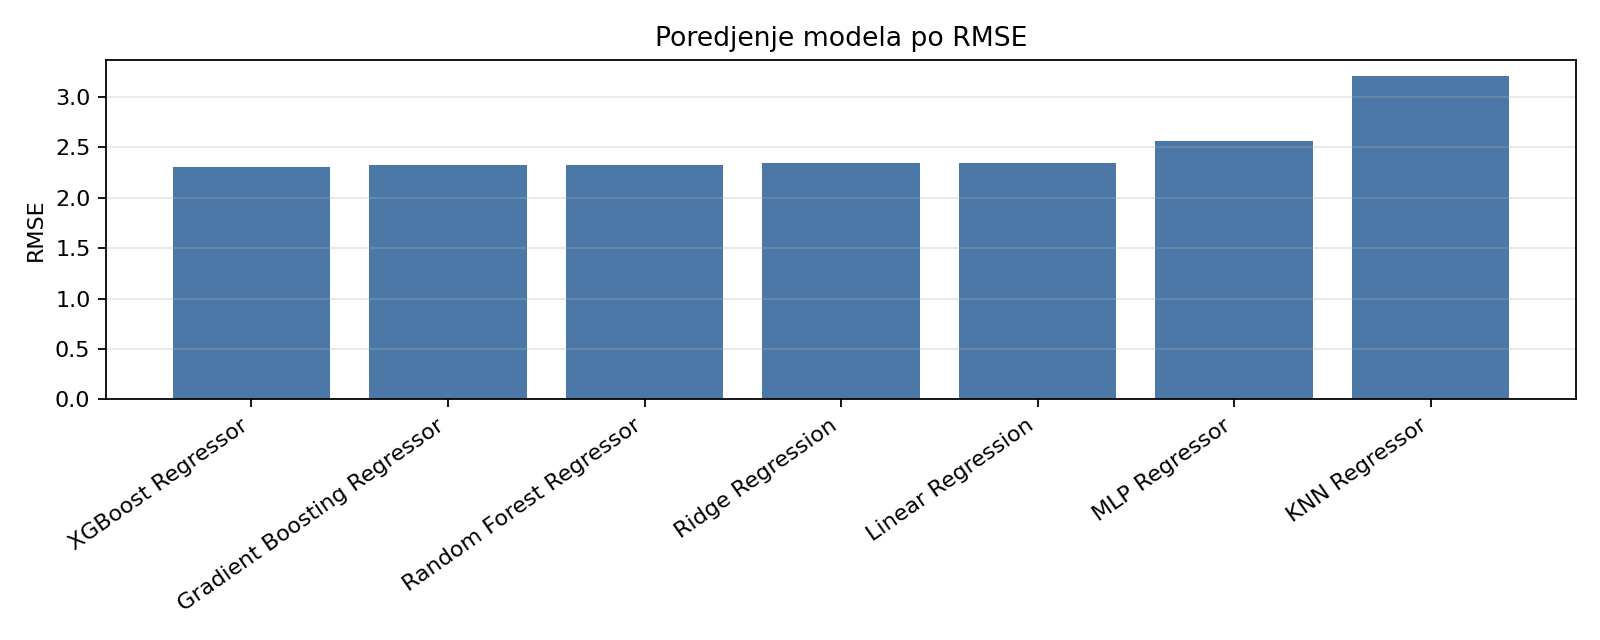

In [3]:
from pathlib import Path
ASSETS = Path('artifacts') / 'defense_assets'

from IPython.display import Image, display

display(Image(filename=ASSETS / 'modeli_rmse.png'))

Ovaj grafikon pokazuje da XGBoost ima najmanju gresku `RMSE = 2.3007`, sto ga cini najboljim modelom za prognozu potraznje na ovom skupu.

## 5. Trend prodaje kroz vreme

Na ovom grafiku vidi se mesecna ukupna prodaja. To pokazuje da podaci imaju vremensku dinamiku i da je smisleno koristiti pristup sa vremenskim atributima.

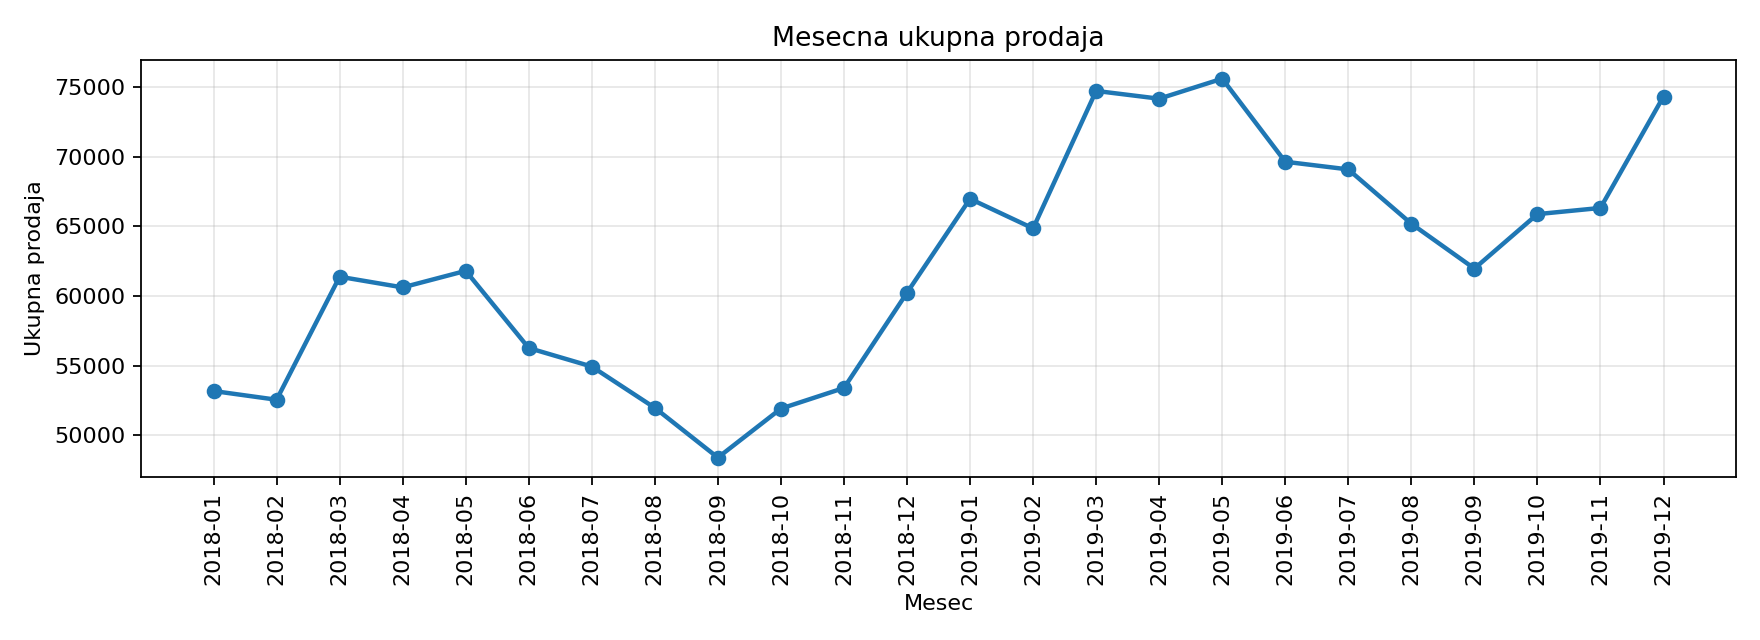

In [4]:
from pathlib import Path
ASSETS = Path('artifacts') / 'defense_assets'

from IPython.display import Image, display

display(Image(filename=ASSETS / 'mesecna_prodaja.png'))

## 6. Primer predikcije

Sledeci grafikon prikazuje poredjenje stvarne i predvidjene prodaje za jedan konkretan par `store-item`. Vizuelno se vidi da model dosta dobro prati realnu prodaju.

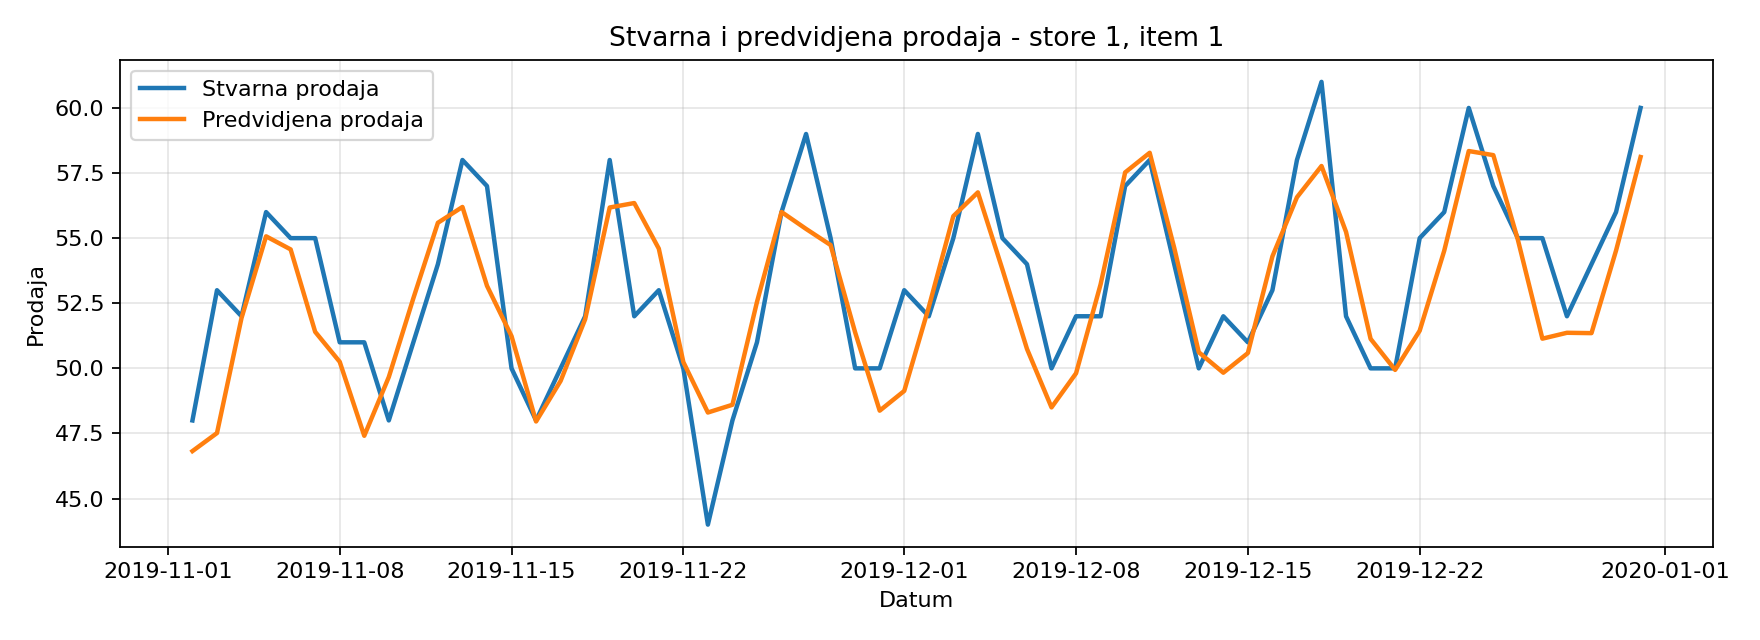

In [5]:
from pathlib import Path
ASSETS = Path('artifacts') / 'defense_assets'

from IPython.display import Image, display

display(Image(filename=ASSETS / 'predikcija_primer.png'))

## 7. Znacaj atributa

Najveci uticaj imaju atributi `lag_7` i `lag_14`, a zatim rolling proseci. To je ocekivano, jer se buduca prodaja kod vremenskih serija najcesce najbolje objasnjava skorijim kretanjem iste serije.

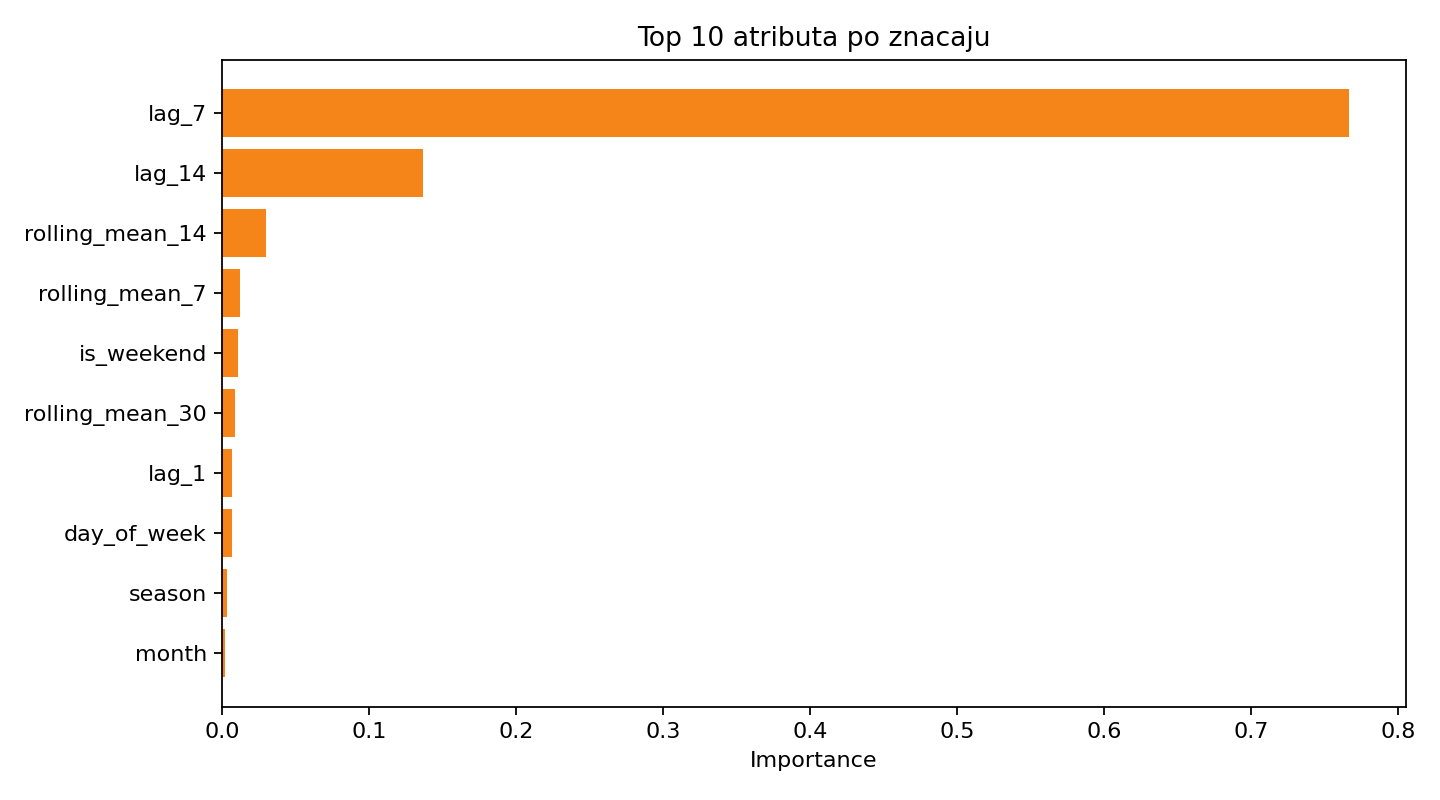

In [6]:
from pathlib import Path
ASSETS = Path('artifacts') / 'defense_assets'

from IPython.display import Image, display

display(Image(filename=ASSETS / 'top_atributi.png'))

## 8. Zalihe i preporuke

Sistem ne staje na predikciji prodaje. Na osnovu procenjene dnevne prodaje, bezbednosne zalihe i reorder point logike generisu se preporuke za dopunu lagera.

In [ ]:
zalihe

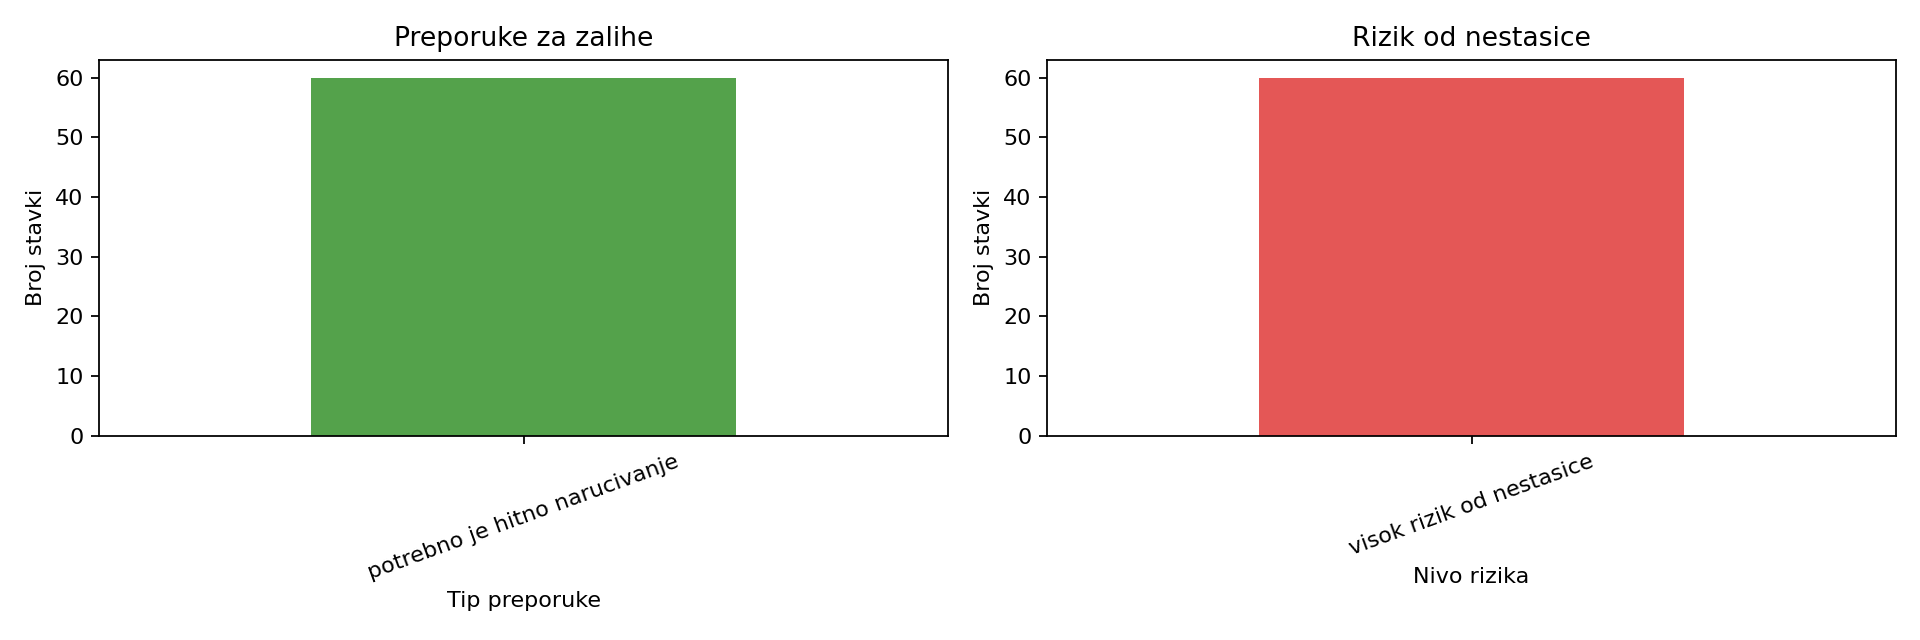

In [7]:
from pathlib import Path
ASSETS = Path('artifacts') / 'defense_assets'

from IPython.display import Image, display

display(Image(filename=ASSETS / 'zalihe_pregled.png'))

Na ovom pokretanju veliki broj stavki ima preporuku za hitno narucivanje, sto ukazuje na visok rizik od nestasice prema proceni modela.

## 9. Zakljucak

Na osnovu dobijenih rezultata mogu da zakljucim:

- najbolji model u ovom pokretanju je **XGBoost Regressor**,
- `R2 = 0.9740` pokazuje da model veoma dobro objasnjava promene u prodaji,
- `MAPE = 6.2119%` pokazuje relativno malu procentualnu gresku,
- klasifikacija nivoa potraznje daje dobar rezultat sa `accuracy = 0.9081`,
- sistem ima prakticnu vrednost jer predikciju prevodi u preporuku za zalihe.

Kao moguca unapredjenja mogu se navesti rad sa originalnim Kaggle skupom, ukljucivanje praznika i promocija, finije podesavanje hiperparametara i dodatna vremenska validacija.